# Customer Review Sentiment Analysis (original notebook)

TF-IDF + Logistic Regression on the IMDb Large Movie Review Dataset.

This is the original exploratory notebook. Cells were reordered so that the notebook runs
top-to-bottom (the Colab version had cells out of execution order); the analysis code is unchanged.
The reusable, tested implementation lives in `src/review_sentiment/`.

> **Evaluation caveat (found during the 2026 refactor).** Section 3 pools the official IMDb train and test sets and re-splits them at random. The dataset authors made the official train and test movies disjoint; after a random re-split about 96% of test reviews share a movie with the training data and roughly 136 test reviews are exact duplicates of training reviews. Re-running this exact model under movie-disjoint splits lowers accuracy from about 0.896 to about 0.883 (see `results/leakage/` and the README). The package in `src/` uses the official split.

## 1. Setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
# !pip install datasets  # Colab only; locally use requirements.txt

In [2]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")  # canonical Hub id; the short alias "imdb" fails with datasets 5.x

In [3]:
import pandas as pd

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

In [4]:
df = pd.concat([train_df, test_df], ignore_index=True)

In [5]:
df = df.rename(columns={
    "text": "review",
    "label": "sentiment"
})

In [6]:
df.head()

,review,sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [7]:
df.shape

(50000, 2)

In [8]:
df["sentiment"].value_counts()

sentiment
0    25000
1    25000
Name: count, dtype: int64

## 2. Text cleaning

In [9]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)          # حذف HTML
    text = re.sub(r"[^a-zA-Z\s]", " ", text)    # حذف اعداد و علائم
    text = re.sub(r"\s+", " ", text).strip()    # حذف فاصله‌های اضافی
    return text

In [10]:
df["clean_review"] = df["review"].apply(clean_text)

In [11]:
df[["review", "clean_review"]].head(3)

,review,clean_review
0,I rented I AM CURIOUS-YELLOW from my video sto...,i rented i am curious yellow from my video sto...
1,"""I Am Curious: Yellow"" is a risible and preten...",i am curious yellow is a risible and pretentio...
2,If only to avoid making this type of film in t...,if only to avoid making this type of film in t...


## 3. Train/test split and TF-IDF features

In [12]:
X = df["clean_review"]
y = df["sentiment"]

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [14]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((40000,), (10000,), (40000,), (10000,))

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2)
)

In [16]:
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [17]:
X_train_tfidf.shape, X_test_tfidf.shape

((40000, 10000), (10000, 10000))

## 4. Logistic Regression model and evaluation

In [18]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [19]:
model.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [20]:
y_pred = model.predict(X_test_tfidf)

In [21]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8964


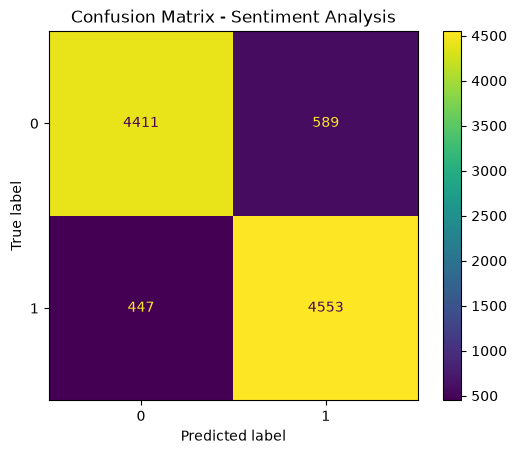

In [22]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Sentiment Analysis")
plt.savefig("../figures/original/confusion_matrix.png", bbox_inches="tight")
plt.show()

In [23]:
accuracy

0.8964

In [24]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.88      0.89      5000
           1       0.89      0.91      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



## 5. Most influential words

In [25]:
import numpy as np
import pandas as pd

feature_names = np.array(vectorizer.get_feature_names_out())
coefficients = model.coef_[0]

In [26]:
top_positive_idx = np.argsort(coefficients)[-15:]
top_positive_words = feature_names[top_positive_idx]
top_positive_scores = coefficients[top_positive_idx]

positive_df = pd.DataFrame({
    "word": top_positive_words,
    "score": top_positive_scores
}).sort_values(by="score", ascending=False)

positive_df

,word,score
14,great,7.214074
13,excellent,6.698923
12,best,5.729858
11,perfect,5.604021
10,wonderful,5.149068
9,amazing,5.094822
8,favorite,4.621234
7,brilliant,4.594651
6,hilarious,4.426813
5,fun,4.362909


In [27]:
top_negative_idx = np.argsort(coefficients)[:15]
top_negative_words = feature_names[top_negative_idx]
top_negative_scores = coefficients[top_negative_idx]

negative_df = pd.DataFrame({
    "word": top_negative_words,
    "score": top_negative_scores
}).sort_values(by="score", ascending=True)

negative_df

,word,score
0,worst,-9.560448
1,awful,-7.824141
2,bad,-7.306991
3,boring,-6.719380
4,waste,-6.676401
5,poor,-6.155433
6,terrible,-6.036625
7,worse,-5.229315
8,horrible,-5.109950
9,disappointment,-5.094761


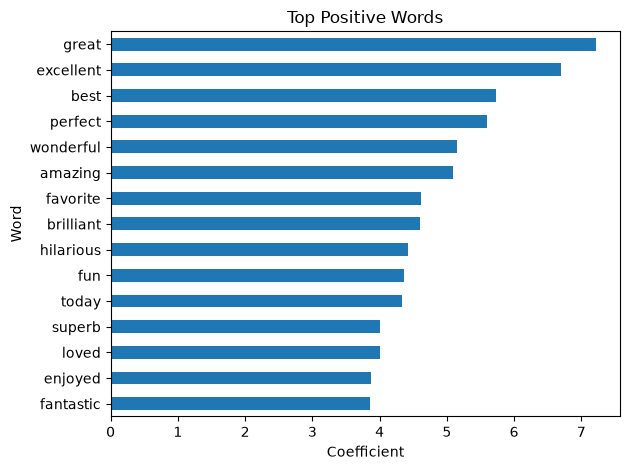

In [28]:
positive_df.sort_values(by="score", ascending=True).plot(
    x="word",
    y="score",
    kind="barh",
    legend=False
)
plt.title("Top Positive Words")
plt.xlabel("Coefficient")
plt.ylabel("Word")
plt.tight_layout()
plt.savefig("../figures/original/top_positive_words.png", bbox_inches="tight")
plt.show()

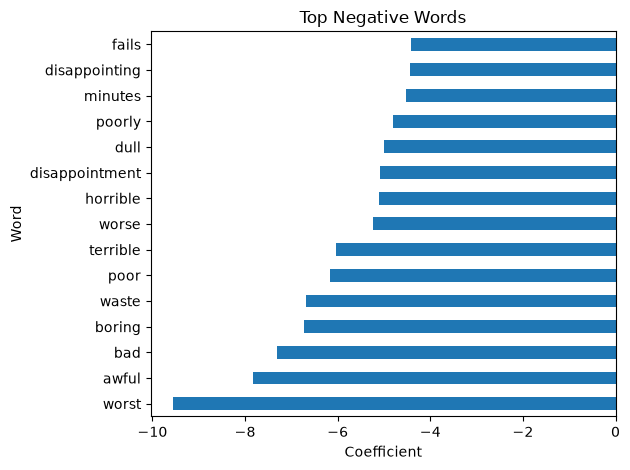

In [29]:
negative_df.sort_values(by="score", ascending=True).plot(
    x="word",
    y="score",
    kind="barh",
    legend=False
)
plt.title("Top Negative Words")
plt.xlabel("Coefficient")
plt.ylabel("Word")
plt.tight_layout()
plt.savefig("../figures/original/top_negative_words.png", bbox_inches="tight")
plt.show()

In [30]:
positive_df.head(10)

,word,score
14,great,7.214074
13,excellent,6.698923
12,best,5.729858
11,perfect,5.604021
10,wonderful,5.149068
9,amazing,5.094822
8,favorite,4.621234
7,brilliant,4.594651
6,hilarious,4.426813
5,fun,4.362909


In [31]:
negative_df.head(10)

,word,score
0,worst,-9.560448
1,awful,-7.824141
2,bad,-7.306991
3,boring,-6.719380
4,waste,-6.676401
5,poor,-6.155433
6,terrible,-6.036625
7,worse,-5.229315
8,horrible,-5.109950
9,disappointment,-5.094761


## 6. Predicting new reviews

In [32]:
sample_reviews = [
    "This movie was fantastic, emotional, and beautifully directed.",
    "The plot was boring and the acting was terrible."
]

In [33]:
sample_reviews_clean = [clean_text(r) for r in sample_reviews]
sample_reviews_tfidf = vectorizer.transform(sample_reviews_clean)
sample_preds = model.predict(sample_reviews_tfidf)
sample_probs = model.predict_proba(sample_reviews_tfidf)

In [34]:
for review, pred, prob in zip(sample_reviews, sample_preds, sample_probs):
    label = "positive" if pred == 1 else "negative"
    print("Review:", review)
    print("Predicted sentiment:", label)
    print("Probabilities:", prob)
    print("-" * 50)

Review: This movie was fantastic, emotional, and beautifully directed.
Predicted sentiment: positive
Probabilities: [0.0198152 0.9801848]
--------------------------------------------------
Review: The plot was boring and the acting was terrible.
Predicted sentiment: negative
Probabilities: [0.99893407 0.00106593]
--------------------------------------------------


## 7. Business insights

In [35]:
content = """
# Business Insights from Sentiment Analysis

1. Sentiment analysis can automatically classify customer feedback.

2. Positive reviews often highlight product quality and enjoyment.

3. Negative reviews frequently mention poor experience or dissatisfaction.

4. Sentiment monitoring helps detect problems early.

5. Customer feedback can guide product improvements.
"""

with open("../docs/business_insights.md", "w") as f:
    f.write(content)

print("business_insights.md created")

business_insights.md created
